# 02 — What we measure

---

Every feature here is a property of the **letter sequence itself**, independent of what the genome codes for.

### GC content
The fraction of letters that are G or C.

### Dinucleotide frequency
How often a given pair of adjacent letters occurs. We track the four GC-containing pairs used in the paper, plus one more:

| Pair | Written | Note |
|---|---|---|
| C then G | CpG | the motif of interest |
| G then C | GpC | |
| G then G | GpG | |
| C then C | CpC | |
| T then A | UpA | **not in the paper**; added as exploratory |

### Observed / expected ratio
Counting pairs directly is misleading, because a GC-rich genome contains more CpG by chance alone. So we divide by what chance predicts:

$$ \mathrm{O/E}(\mathrm{CpG}) = \frac{f(\mathrm{CpG})}{f(\mathrm{C}) \times f(\mathrm{G})} $$

A value near **1** means as common as chance predicts; **below 1** means the virus is avoiding that pair.

### GC3 and GC12
GC content split by position inside the codon. **GC3** is the third position, where most changes are synonymous and do not alter the protein. **GC12** is the first and second, where most changes do alter it.

Comparing how fast the two move separates pressure acting on the RNA from pressure acting on the protein — the same logic as comparing dS with dN. The paper reports GC3 changing **5.65× faster** than GC12 in influenza.

---

In [1]:
import sys, os, subprocess
sys.path.insert(0, os.path.abspath("../src"))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = os.path.abspath("..")          # repo root; the R scripts expect to run from here
pd.set_option("display.width", 130)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})
PAL = {"A": "#2C7FB8", "B": "#C62824"}    # same colours as the R figures

def run_r(script="R/figures.R"):
    """Run the R figure script from the repo root and report what it wrote."""
    r = subprocess.run(["Rscript", script], capture_output=True, text=True, cwd=ROOT)
    print(r.stdout.strip() or r.stderr.strip()[-400:])

def show(fig):
    """Display a figure from results/figures/ inline."""
    display(Image(os.path.join(ROOT, "results", "figures", fig)))
from rsv import composition

## 2.1  The functions, on a short example

All measurements come from `src/rsv/composition.py`. Ambiguous positions are skipped rather than guessed.

In [2]:
demo = "ATGGCGTTAACGCGTAAATTACGATAG"
f = composition.all_features(demo, coding=True)
for k in ["gc_content", "gc3", "gc12", "per1k_CG", "oe_CG", "oe_TA"]:
    print(f"{k:12s} {f[k]:.4f}")

gc_content   0.4074
gc3          0.4444
gc12         0.3889
per1k_CG     153.8462
oe_CG        4.0055
oe_TA        1.7802


## 2.2  The measurements across all genomes

Here `GENOME` means the ten coding regions concatenated, which is how the paper defines genome-level GC, GC3 and GC12 — it keeps the reading frame well defined.

In [3]:
g = pd.read_csv("../data/processed/rsv_gene_features.tsv", sep="\t")
genome = g[g.gene == "GENOME"]
cols = ["gc_content", "gc3", "gc12", "oe_CG", "oe_GC", "oe_GG", "oe_CC", "oe_TA"]
genome.groupby("Subtype")[cols].mean().round(4)

,gc_content,gc3,gc12,oe_CG,oe_GC,oe_GG,oe_CC,oe_TA
Subtype,,,,,,,,
A,0.3373,0.2951,0.3584,0.2361,1.0071,1.0545,1.0689,0.8981
B,0.3378,0.2949,0.3592,0.2420,1.0947,0.9837,1.0271,0.8990


### Reading that table

**CpG O/E sits far below 1 in both subtypes.** RSV carries only a fraction of the CpG pairs its base composition would predict. The other GC pairs sit near or above 1, so the effect is specific to CpG rather than a general shortage of G and C.

**GC3 is much lower than GC12**, which is typical: third positions are free to drift because changing them usually does not change the protein.

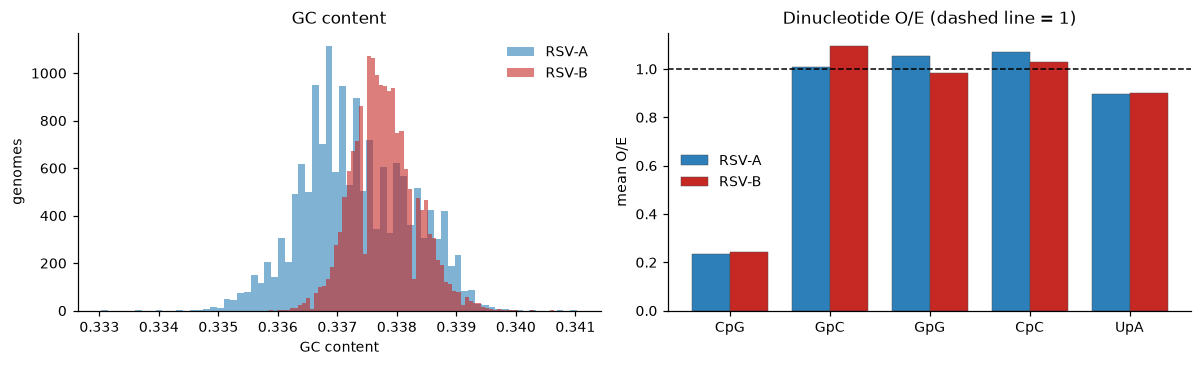

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for s in "AB":
    x = genome[genome.Subtype == s]
    ax[0].hist(x.gc_content, bins=70, alpha=.6, color=PAL[s], label=f"RSV-{s}")
ax[0].set_xlabel("GC content"); ax[0].set_ylabel("genomes")
ax[0].set_title("GC content"); ax[0].legend(frameon=False)
oe = ["oe_CG", "oe_GC", "oe_GG", "oe_CC", "oe_TA"]
names = ["CpG", "GpC", "GpG", "CpC", "UpA"]
pos = np.arange(len(oe))
for i, s in enumerate("AB"):
    x = genome[genome.Subtype == s]
    ax[1].bar(pos + (i - .5) * .38, [x[c].mean() for c in oe], width=.38,
              color=PAL[s], label=f"RSV-{s}", edgecolor="0.3", linewidth=.3)
ax[1].axhline(1, ls="--", lw=1, c="k")
ax[1].set_xticks(pos); ax[1].set_xticklabels(names)
ax[1].set_ylabel("mean O/E"); ax[1].set_title("Dinucleotide O/E (dashed line = 1)")
ax[1].legend(frameon=False)
plt.tight_layout(); plt.show()

Only **CpG**, and to a lesser extent **UpA**, fall clearly below the dashed line. That is the pattern reported across RNA viruses that circulate in humans.